# Heterogeneous Asset Returns

**Table of contents**<a id='toc0_'></a>    
- 1. [Preliminary: Working with 2 exogenous states](#toc1_)    
- 2. [Q1: PE household problem](#toc2_)    
- 3. [Q2: New market-clearing condition](#toc3_)    
- 4. [Q3: GE calibration](#toc4_)    
- 5. [Q4: Comparison with the standard HA model](#toc5_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':0.25,'grid.linestyle':'--','font.size':14})

from consav.markov import log_rouwenhorst, rouwenhorst

from HANCModel import HANCModelClass

## 1. <a id='toc1_'></a>[Preliminary: Working with 2 exogenous states](#toc0_)

In GEModelTools the household variables ($c$, $a$, $\boldsymbol{D}$) are arrays of size $N_{fix} \times N_z \times N_a$: $N_{fix}$ fixed states, $N_z$ stochastic discrete states and $N_a$ asset grid points.

Here households have two stochastic states, productivity $e_{it}$ and the excess return $r^X_{it}$. We discretize them with 5 and 7 points, and stack them into one state $z$ with $N_z = N_e N_r$ points.

In [2]:
Ne = 5
rho_e = 0.96
sigma_e = 0.1
e_grid,e_trans,e_ergodic,_,_ = log_rouwenhorst(rho=rho_e,sigma=sigma_e,n=Ne)
print(f'mean e = {e_ergodic@e_grid:.2f}')

Nr = 7
rho_r = 0.7
rX_mean = 0.02
sigma_r = 0.01
r_grid,r_trans,r_ergodic,_,_ = rouwenhorst(mu=rX_mean*(1-rho_r),rho=rho_r,sigma=sigma_r,n=Nr)
print(f'mean r = {r_ergodic@r_grid:.2f}')

mean e = 1.00
mean r = 0.02


The joint transition matrix and ergodic distribution are the *Kronecker products* of the two.

In [3]:
Nz = Ne*Nr
z_trans = np.kron(r_trans,e_trans)
z_ergodic = np.kron(r_ergodic,e_ergodic)
print(f'{z_trans.shape = }')

assert np.allclose(z_trans.sum(axis=1),1.0)
assert np.allclose(z_ergodic@z_trans,z_ergodic)

z_trans.shape = (35, 35)


Since $r^X$ comes first in the Kronecker product, state `i_z` is `i_r = i_z // Ne` and `i_e = i_z % Ne`.

As a check, we compute cash-on-hand $m = (1+r^X)a_{-1} + e$ with $a_{-1}=2$ in every state, and take the average.

In [4]:
a_lag = 2.0
m = np.zeros(Nz)

for i_z in range(Nz):
    i_r = i_z // Ne
    i_e = i_z % Ne
    m[i_z] = (1+r_grid[i_r])*a_lag + e_grid[i_e]

print(f'average m = {z_ergodic@m:.4f}, should be {(1+rX_mean)*a_lag + e_ergodic@e_grid:.4f}')

average m = 3.0400, should be 3.0400


## 2. <a id='toc2_'></a>[Q1: PE household problem](#toc0_)

Solve the household problem in partial equilibrium given $r=0.04$, $w=0.64$, $\beta=0.89$ and $\bar{r}^X=0$.

Note: you need to update `prepare_hh_ss` (in `steady_state.py`) and `solve_hh_backwards` (in `household_problem.py`).

In [5]:
model = HANCModelClass(name='het_returns')
par = model.par
ss = model.ss

ss.r = 0.04
ss.w = 0.64
par.beta = 0.89
par.rX_mean = 0.0

model.solve_hh_ss()
model.simulate_hh_ss()

In the standard HA model the average return is $rA/A = r$. What is the average return here, `ss.RETURNS_hh/ss.A_hh`? Is it equal to `ss.r + par.rX_mean`, as one might expect?

In [6]:
ss.RETURNS_hh/ss.A_hh

np.float64(0.06524008818375637)

No. The average return is about 6.5%, above $r + \bar{r}^X = 4\%$. Households with a high $r^X$ save more, so the wealth-weighted average return is higher.

## 3. <a id='toc3_'></a>[Q2: New market-clearing condition](#toc0_)

Why do we need a new market-clearing condition? Write it down.

**Answer:** in the standard HANC model everyone earns $r_t = F_K - \delta$, so capital market clearing $K_t = A^{hh}_t$ is enough.

Here households earn $r_t + r^X_{it}$, and the average return is wealth-weighted:
$$
\frac{\int (r_t + r^X_{it})\, a_{it-1}\, d\boldsymbol{D}_t}{\int a_{it-1}\, d\boldsymbol{D}_t} = r_t + \bar{r}^X + \frac{\text{Cov}(r^X_{it}, a_{it-1})}{\mathbb{E}[a_{it-1}]}
$$
Households with a high $r^X$ save more, so the covariance is positive (Q1: about 6.5% instead of 4%). The average return depends on the wealth distribution, and nothing yet ties the returns paid to households to what capital earns.

The new condition: the mutual fund can only pay out what capital earns,
$$
(F_K - \delta) K_{t-1} = \int (r_t + r^X_{it})\, a_{it-1}\, d\boldsymbol{D}_t .
$$
Given $K_{t-1} = A^{hh}_{t-1}$, this is $\int r^X_{it}\, a_{it-1}\, d\boldsymbol{D}_t = 0$: excess returns only redistribute capital income. It adds one unknown, $\bar{r}^X$, which comes out negative in the calibration. This is the same idea as the capital-income condition in Hubmer, Krusell and Smith (2021).

## 4. <a id='toc4_'></a>[Q3: GE calibration](#toc0_)

Calibrate $\beta$ and $\bar{r}^X$ so that households hold $A^{hh} = K$ and the mutual fund pays out exactly $rK$ (see `find_ss` in `steady_state.py`).

In [7]:
model.find_ss(do_print=True)

beta = 0.9550, rX_mean = -0.0044
clearing_A = -1.16e-07, RETURNS_hh/A_hh = 0.0400, clearing_Y = 6.23e-05


## 5. <a id='toc5_'></a>[Q4: Comparison with the standard HA model](#toc0_)

As a benchmark, solve the standard HA model without return heterogeneity: $\sigma_r = 0$, so the calibration gives $\bar{r}^X=0$.

In [8]:
model_base = HANCModelClass(name='base',par={'sigma_r':0.0})
model_base.find_ss(x0=np.array([0.949,0.0]),do_print=True)

beta = 0.9541, rX_mean = 0.0000
clearing_A = 6.64e-09, RETURNS_hh/A_hh = 0.0400, clearing_Y = 1.94e-08


Compare the top wealth shares of the two models.

In [9]:
for model_plot,label in [(model_base,'Standard HA'),(model,'Het. returns')]:
    D_a = model_plot.ss.D.sum(axis=(0,1))
    cdf = np.cumsum(D_a)
    lorenz = np.cumsum(model_plot.par.a_grid*D_a)/np.sum(model_plot.par.a_grid*D_a)
    top10,top1,top01 = 1-np.interp([0.9,0.99,0.999],cdf,lorenz)
    print(f'{label:12s}: top 10% = {top10:.1%}, top 1% = {top1:.1%}, top 0.1% = {top01:.1%}, at constraint = {D_a[0]:.1%}')

Standard HA : top 10% = 35.5%, top 1% = 5.6%, top 0.1% = 0.7%, at constraint = 9.4%
Het. returns: top 10% = 53.9%, top 1% = 21.7%, top 0.1% = 11.2%, at constraint = 11.8%


Compare the Pareto tail of wealth with US data from GKKOC (2023), which has a slope of $-1.52$. One unit of model income $wL$ corresponds to \$90,000.

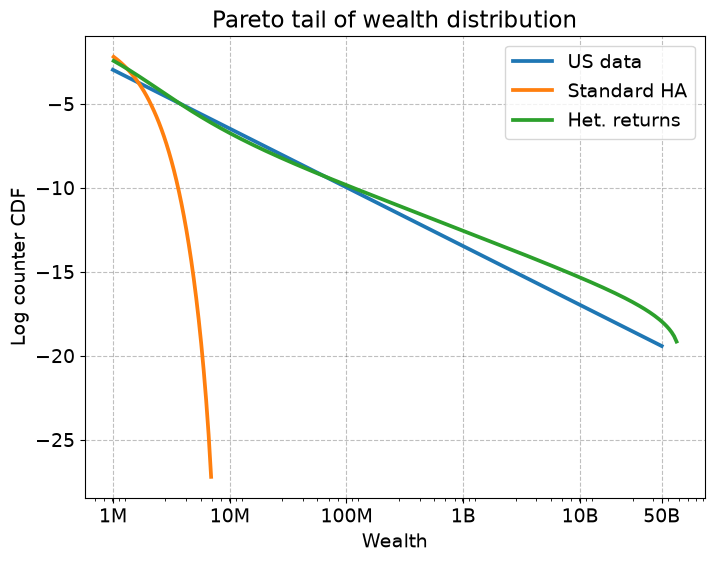

In [10]:
wealth_dollars = np.array([1e6,1e7,1e8,1e9,1e10,5e10])
a_ticks = wealth_dollars/90_000*ss.w*ss.L
a_labels = ['1M','10M','100M','1B','10B','50B']
a_data = np.linspace(a_ticks[0],a_ticks[-1],1000)

fig, ax = plt.subplots(figsize=(8,6))
ax.plot(a_data,-1.52*np.log(a_data),label='US data',lw=2.7)

for model_plot,label in [(model_base,'Standard HA'),(model,'Het. returns')]:
    counter_cdf = 1-np.cumsum(model_plot.ss.D.sum(axis=(0,1)))
    I = (model_plot.par.a_grid > a_ticks[0]) & (counter_cdf > 0)
    ax.plot(model_plot.par.a_grid[I],np.log(counter_cdf[I]),label=label,lw=2.7)

ax.set_xscale('log')
ax.set_xticks(a_ticks,labels=a_labels)
ax.set_xlabel('Wealth')
ax.set_ylabel('Log counter CDF')
ax.set_title('Pareto tail of wealth distribution')
ax.legend();

What does return heterogeneity change? Compare with the US data: a top 1% wealth share of about 35% and a tail slope of $-1.52$.

**Answer:** return heterogeneity gives some households a growth factor above one, which is the random growth of the lecture (route 2).
The top 1% share rises from 5.6% to 21.7%, and the top 0.1% share from 0.7% to 11.2%.
The standard model has no Pareto tail: its counter CDF falls off a cliff below $10M.
With heterogeneous returns, the tail is close to a straight line with a slope of about 569Xl1.47$, close to the 569Xl1.52$ in the data.
The top 1% share is still below the 35% in the data.